# Client Data Analysis Report
**Prepared by:** Thabiso  
**Date:** 17 November 2026  
**Client:** [Claude]  
**Assessment window:** 17:00–20:00 SAST

---

In [1]:
import sqlite3, pandas as pd
import matplotlib.pyplot as plt

# --- Connect (adjust filename to the one Ruben sends) ---
DB = "practice_shop.db"  # practice file; change for the real assessment
con = sqlite3.connect(DB)

# --- Schema & table sizes ---
tables = pd.read_sql("SELECT name FROM sqlite_master WHERE type='table'", con)
for t in tables['name']:
    n = pd.read_sql(f"SELECT COUNT(*) c FROM {t}", con)['c'][0]
    print(f"{t}: {n} rows")

customers: 206 rows
products: 20 rows
orders: 1827 rows
order_items: 3644 rows


In [ ]:
#Rows in orders table and how many disticnt order_id's ,DAta quality check for duplicate order_id's
orders_count = pd.read_sql("""
Select Count(*) as total_orders,Count(Distinct order_id) as distinct_orders,
Count(*) - Count(Distinct order_id) as duplicate_orders
 from orders

 """, con)
print(orders_count)

   total_orders  distinct_orders  duplicate_orders
0          1827             1822                 5


In [21]:
#customers who appear more than once

count_customers = pd.read_sql("""
SELECT
    email,
    GROUP_CONCAT(customer_id) AS customer_ids,
    COUNT(*) AS records
FROM customers
GROUP BY email
HAVING COUNT(*) > 1
""", con)

print(count_customers)

                          email customer_ids  records
0     dylan.botha110@mail.co.za      110,202        2
1    johan.sithole71@mail.co.za       71,204        2
2    johan.van.wyk13@mail.co.za       13,205        2
3  lindiwe.pillay194@mail.co.za      194,203        2
4    pieter.molefe93@mail.co.za       93,201        2
5    sipho.sithole72@mail.co.za       72,206        2


In [28]:
#How many Disticnt orders belong to a customer id that does not exist in the customers table
missing_customers = pd.read_sql("""Select Count(Distinct order_id) as missing_orders from orders where 
customer_id not in (Select customer_id from customers where customer_id is not null)

 """,con)

print(missing_customers)


#try two
missingx2_Customers=pd.read_sql("""
Select Count(Distinct order_id) as missing_orders from orders o
 left join customers c using(customer_id) where c.customer_id is null
 """,con)

print(missingx2_Customers)

   missing_orders
0               8
   missing_orders
0               8


In [35]:
#How many deliverd orders have no delivery date

null_delivery_date=pd.read_sql("""
Select Count(*) as no_deliery_date from orders where status='delivered' AND delivery_date is NUll
 """,con)


print(null_delivery_date)


quantity_delivery_date=pd.read_sql("""
Select Count(*) as quantity from order_items where quantity<=0
 """,con)


print(quantity_delivery_date)

   no_deliery_date
0               14
   quantity
0         4


In [43]:
#Cleaning data for analysis

con.executescript('''
DROP VIEW IF EXISTS orders_clean;
DROP VIEW IF EXISTS customers_clean;
DROP VIEW IF EXISTS products_clean;
DROP VIEW IF EXISTS order_items_clean;
CREATE VIEW orders_clean AS SELECT DISTINCT * FROM orders;
CREATE VIEW products_clean AS SELECT DISTINCT * FROM products;
CREATE VIEW customers_clean AS
SELECT DISTINCT customer_id, name,email,
       UPPER(TRIM(city)) AS city,
       UPPER(TRIM(name)) AS name
FROM customers;
CREATE VIEW order_items_clean AS SELECT DISTINCT * FROM order_items WHERE quantity > 0;
''')
print("Clean views ready: orders_clean, customers_clean, products_clean, order_items_clean")

Clean views ready: orders_clean, customers_clean, products_clean, order_items_clean


In [53]:

#Total revenue by product category highest first
total_revenue_by_category = pd.read_sql("""
Select p.category as category ,Sum(o.quantity*o.unit_price) as Total_revenue from order_items_clean o 
join orders_clean x using(order_id)
join  products_clean p using(product_id) 
where x.status <>'cancelled' 
Group By p.category Order BY Sum(o.quantity*o.unit_price) DESC
 """,con)

print(total_revenue_by_category)

      category  Total_revenue
0       Office     2073811.30
1  Electronics     1579375.91
2         Home     1018616.88
3      Fitness      385661.99


In [59]:
#Top 5 customers by revenue
top_customers_by_revenue = pd.read_sql("""Select c.name, SUM(o.quantity*o.unit_price) 
from order_items_clean o
Join orders_clean x using(order_id) 
join customers_clean c using(customer_id)
where x.status <>'cancelled' 
Group By email 
Order By SUM(o.quantity*o.unit_price) Desc 
Limit 5""",con)

print(top_customers_by_revenue)

              name  SUM(o.quantity*o.unit_price)
0    Sipho Sithole                      76295.36
1    Pieter Molefe                      64434.94
2     Sizwe Venter                      62484.80
3  Lindiwe Mokoena                      59793.85
4    Kabelo Pillay                      54734.13


In [62]:
cancellation_rate = pd.read_sql("""
WITH category_orders AS (
    SELECT
        p.category,
        COUNT(DISTINCT o.order_id) AS total_orders,
        COUNT(DISTINCT CASE
            WHEN x.status = 'cancelled' THEN x.order_id
        END) AS cancelled_orders
    FROM orders_clean x
    JOIN order_items_clean o USING(order_id)
    JOIN products_clean p USING(product_id)
    GROUP BY p.category
)

SELECT
    category,
    total_orders,
    cancelled_orders,
    ROUND(100.0 * cancelled_orders / total_orders, 2) AS cancellation_rate
FROM category_orders
ORDER BY cancellation_rate DESC
""", con)

print(cancellation_rate)

      category  total_orders  cancelled_orders  cancellation_rate
0      Fitness           363                59              16.25
1       Office           349                16               4.58
2         Home           483                22               4.55
3  Electronics           626                27               4.31


      month  monthly_revenue  previous_month_revenue  mom_percentage_change
0   2025-01        237665.00                     NaN                    NaN
1   2025-02        216583.79               237665.00                  -8.87
2   2025-03        319140.18               216583.79                  47.35
3   2025-04        331758.83               319140.18                   3.95
4   2025-05        333943.68               331758.83                   0.66
5   2025-06        411183.23               333943.68                  23.13
6   2025-07        382505.94               411183.23                  -6.97
7   2025-08        466429.44               382505.94                  21.94
8   2025-09        476854.79               466429.44                   2.24
9   2025-10        567697.16               476854.79                  19.05
10  2025-11        570098.43               567697.16                   0.42
11  2025-12        743605.61               570098.43                  30.43


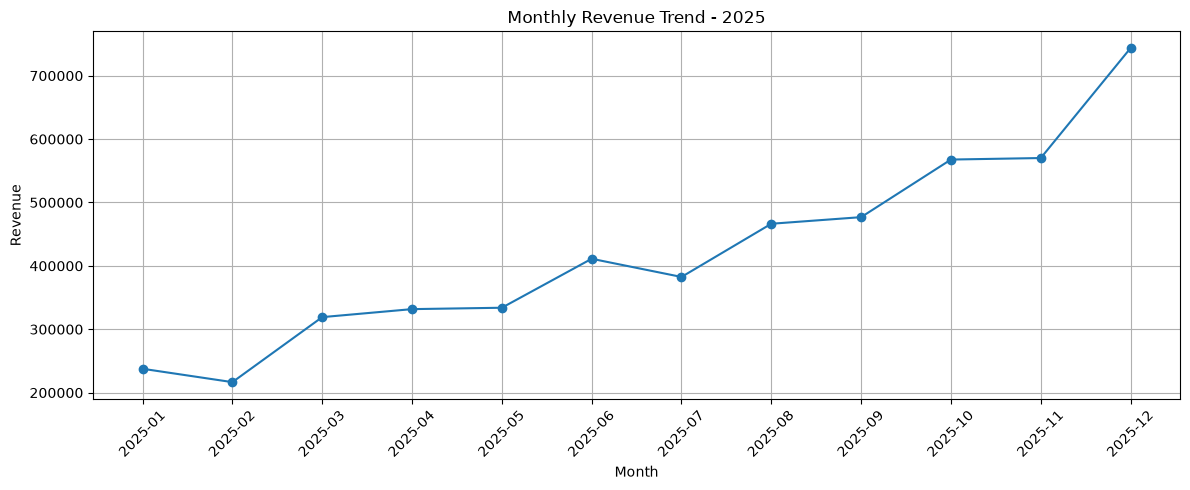

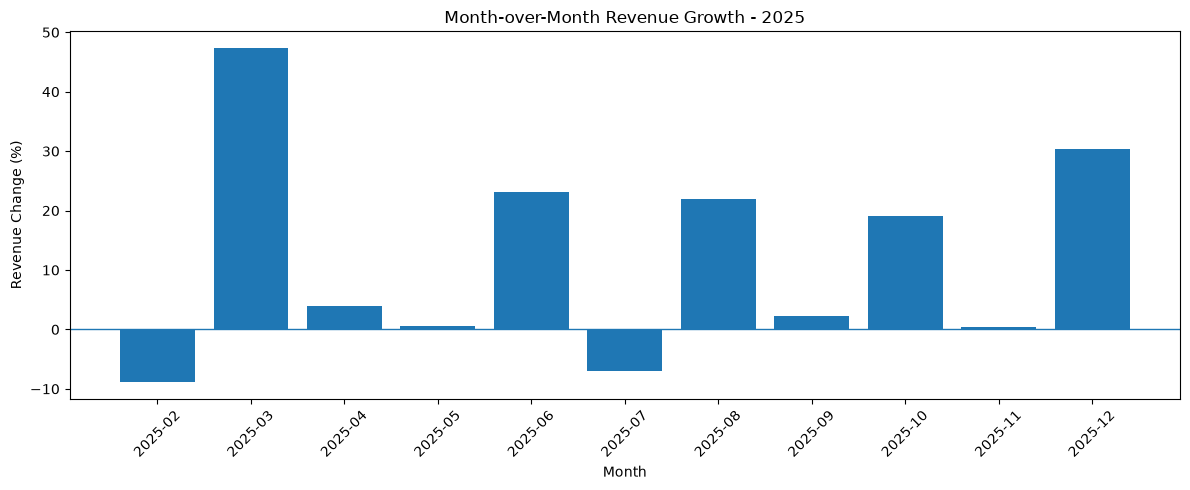

In [65]:
#Month revenue for 2025 with the month over month % change.Use a window function

monthly_revenue = pd.read_sql("""
SELECT
    strftime('%Y-%m', x.order_date) AS month,
    SUM(o.quantity * o.unit_price) AS monthly_revenue,

    LAG(SUM(o.quantity * o.unit_price)) OVER (
        ORDER BY strftime('%Y-%m', x.order_date)
    ) AS previous_month_revenue,

    ROUND(
        100.0 * (
            SUM(o.quantity * o.unit_price) -
            LAG(SUM(o.quantity * o.unit_price)) OVER (
                ORDER BY strftime('%Y-%m', x.order_date)
            )
        ) /
        NULLIF(
            LAG(SUM(o.quantity * o.unit_price)) OVER (
                ORDER BY strftime('%Y-%m', x.order_date)
            ), 0
        ), 2
    ) AS mom_percentage_change

FROM order_items_clean o
JOIN orders_clean x USING(order_id)
WHERE x.status <> 'cancelled'
  AND strftime('%Y', x.order_date) = '2025'
GROUP BY strftime('%Y-%m', x.order_date)
ORDER BY month
""", con)

print(monthly_revenue)

import matplotlib.pyplot as plt

# Monthly revenue trend
plt.figure(figsize=(12, 5))
plt.plot(
    monthly_revenue['month'],
    monthly_revenue['monthly_revenue'],
    marker='o'
)

plt.title('Monthly Revenue Trend - 2025')
plt.xlabel('Month')
plt.ylabel('Revenue')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()


# Month-over-month percentage change
plt.figure(figsize=(12, 5))
plt.bar(
    monthly_revenue['month'],
    monthly_revenue['mom_percentage_change']
)

plt.title('Month-over-Month Revenue Growth - 2025')
plt.xlabel('Month')
plt.ylabel('Revenue Change (%)')
plt.axhline(y=0, linewidth=1)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [68]:
revenue_by_category = pd.read_sql("""
SELECT
    strftime('%m', o.order_date) AS month,
    SUM(CASE WHEN p.category = 'Electronics' THEN oi.quantity * oi.unit_price ELSE 0 END) AS Electronics,
    SUM(CASE WHEN p.category = 'Furniture' THEN oi.quantity * oi.unit_price ELSE 0 END) AS Furniture,
    SUM(CASE WHEN p.category = 'Clothing' THEN oi.quantity * oi.unit_price ELSE 0 END) AS Clothing
FROM order_items_clean oi
JOIN orders_clean o USING(order_id)
JOIN products_clean p USING(product_id)
WHERE strftime('%Y', o.order_date) = '2025'
  AND strftime('%m', o.order_date) IN ('08', '09', '10')
  AND o.status <> 'cancelled'
GROUP BY strftime('%m', o.order_date)
ORDER BY month;
""", con)

print(revenue_by_category)

  month  Electronics  Furniture  Clothing
0    08    145474.88          0         0
1    09     24001.51          0         0
2    10    161118.88          0         0


In [70]:
#top 2 products by revenue in each category use rank or row_number

top_products = pd.read_sql("""
WITH product_revenue AS (
    SELECT
        p.category,
        p.product_name,
        SUM(oi.quantity * oi.unit_price) AS total_revenue
    FROM order_items_clean oi
    JOIN orders_clean o USING(order_id)
    JOIN products_clean p USING(product_id)
    WHERE o.status <> 'cancelled'
    GROUP BY p.category, p.product_id, p.product_name
),
ranked_products AS (
    SELECT
        category,
        product_name,
        total_revenue,
        ROW_NUMBER() OVER (
            PARTITION BY category
            ORDER BY total_revenue DESC
        ) AS ranking
    FROM product_revenue
)
SELECT category, product_name, total_revenue, ranking
FROM ranked_products
WHERE ranking <= 2
ORDER BY category, ranking;
""", con)

print(top_products)

      category      product_name  total_revenue  ranking
0  Electronics     Smart Speaker      531285.42        1
1  Electronics  Wireless Earbuds      365641.21        2
2      Fitness      Dumbbell Set      222495.90        1
3      Fitness           Gym Bag       74040.52        2
4         Home         Air Fryer      459239.82        1
5         Home       Bedding Set      305840.92        2
6       Office     Standing Desk     1088395.03        1
7       Office      Office Chair      537266.34        2


In [79]:
#By customer city ,Show delivere orders ,average days from order to delivery and the % delivered in more than 5 days.City names are inconsistent
#e.g)JHB,pretoria,PORT Elizabeth).Standadise them first

deliver_orders_by_city = pd.read_sql("""
WITH standardised_customers AS (
    SELECT
        customer_id,
        CASE
            WHEN UPPER(TRIM(city)) IN ('JHB', 'JOHANNESBURG')
                THEN 'JOHANNESBURG'
            WHEN UPPER(TRIM(city)) IN ('GQEBERHA', 'PORT ELIZABETH')
                THEN 'GQEBERHA'
            ELSE UPPER(TRIM(city))
        END AS city
    FROM customers_clean
),
delivery_metrics AS (
    SELECT
        c.city,
        o.order_id,
        julianday(o.delivery_date) - julianday(o.order_date) AS delivery_days
    FROM orders_clean o
    JOIN standardised_customers c USING(customer_id)
    WHERE o.status = 'delivered'
)
SELECT
    city,
    COUNT(DISTINCT order_id) AS delivered_orders,
    ROUND(AVG(delivery_days), 2) AS avg_delivery_days,
    ROUND(
        100.0 * COUNT(DISTINCT CASE
            WHEN delivery_days > 5 THEN order_id
        END) / COUNT(DISTINCT order_id), 2
    ) AS delivered_over_5_days_pct
FROM delivery_metrics
GROUP BY city
ORDER BY delivered_orders DESC;
""", con)

print(deliver_orders_by_city)

           city  delivered_orders  avg_delivery_days  \
0  JOHANNESBURG               391               3.60   
1      PRETORIA               314               3.40   
2      GQEBERHA               312               3.58   
3     CAPE TOWN               302               3.39   
4        DURBAN               301               4.64   

   delivered_over_5_days_pct  
0                       8.44  
1                       8.60  
2                      11.86  
3                      10.93  
4                      26.91  


      month          city  avg_delivery_days
0   2025-01     CAPE TOWN               3.14
1   2025-01        DURBAN               3.42
2   2025-01      GQEBERHA               3.42
3   2025-01  JOHANNESBURG               3.78
4   2025-01      PRETORIA               3.36
5   2025-02     CAPE TOWN               3.50
6   2025-02        DURBAN               3.54
7   2025-02      GQEBERHA               3.75
8   2025-02  JOHANNESBURG               3.42
9   2025-02      PRETORIA               3.90
10  2025-03     CAPE TOWN               3.18
11  2025-03        DURBAN               3.95
12  2025-03      GQEBERHA               2.75
13  2025-03  JOHANNESBURG               3.88
14  2025-03      PRETORIA               3.10
15  2025-04     CAPE TOWN               3.19
16  2025-04        DURBAN               3.53
17  2025-04      GQEBERHA               3.86
18  2025-04  JOHANNESBURG               3.23
19  2025-04      PRETORIA               3.53
20  2025-05     CAPE TOWN               3.80
21  2025-0

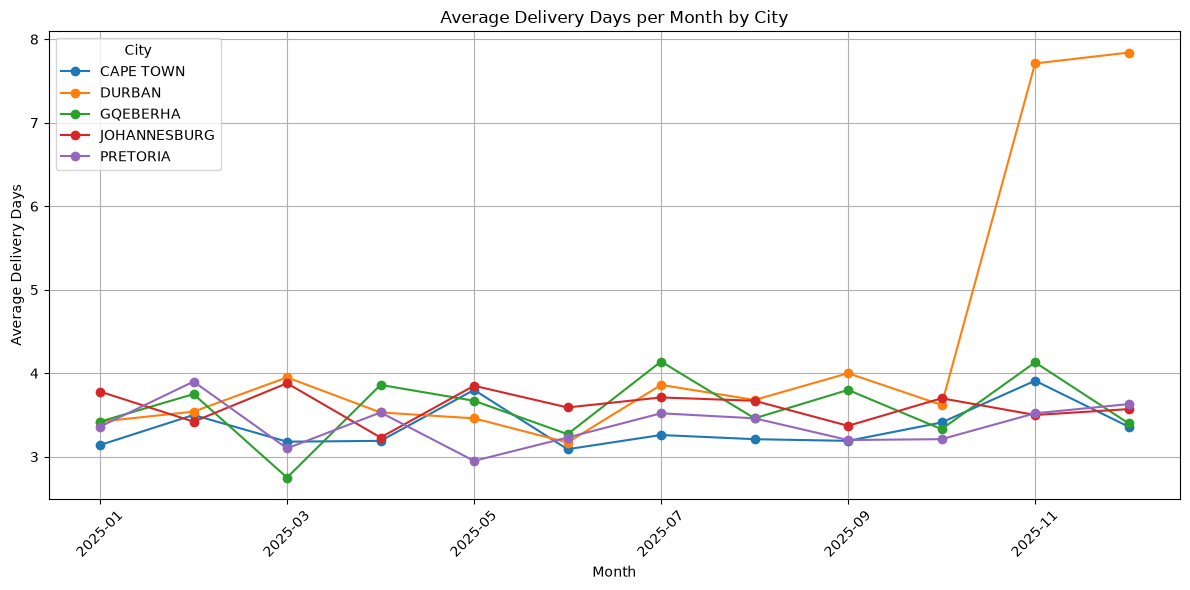

In [80]:
monthly_delivery = pd.read_sql("""
WITH standardised_customers AS (
    SELECT
        customer_id,
        CASE
            WHEN UPPER(TRIM(city)) IN ('JHB', 'JOHANNESBURG')
                THEN 'JOHANNESBURG'
            WHEN UPPER(TRIM(city)) IN ('GQEBERHA', 'PORT ELIZABETH')
                THEN 'GQEBERHA'
            ELSE UPPER(TRIM(city))
        END AS city
    FROM customers_clean
)
SELECT
    strftime('%Y-%m', o.order_date) AS month,
    c.city,
    ROUND(AVG(
        julianday(o.delivery_date) - julianday(o.order_date)
    ), 2) AS avg_delivery_days
FROM orders_clean o
JOIN standardised_customers c USING(customer_id)
WHERE o.status = 'delivered'
GROUP BY month, c.city
ORDER BY month, c.city;
""", con)

print(monthly_delivery)
import matplotlib.pyplot as plt

delivery_pivot = monthly_delivery.pivot(
    index='month',
    columns='city',
    values='avg_delivery_days'
)

delivery_pivot.plot(
    kind='line',
    marker='o',
    figsize=(12, 6)
)

plt.title('Average Delivery Days per Month by City')
plt.xlabel('Month')
plt.ylabel('Average Delivery Days')
plt.xticks(rotation=45)
plt.legend(title='City')
plt.grid(True)
plt.tight_layout()
plt.show()